In [ ]:
# Extraction of IBM median of measurment error and CZ error(MEADIANS)
from qiskit_ibm_runtime.fake_provider import FakeMiami, FakeKingston, FakeBoston, FakeManilaV2
import numpy as np

backend = FakeManilaV2()
backend = FakeBoston()
backend = FakeKingston()
backend = FakeMiami()

p_cx = np.mean([p.error for p in backend.target["cz"].values() if p and p.error])
p_meas = np.mean(
    [p.error for p in backend.target["measure"].values() if p and p.error]
)
p_cx=0.2
p_meas=.5
print(p_cx)
print(p_meas)

0.2
0.5


In [52]:
from IPython import display
from IPython.utils import contexts
from IPython import display
import pymatching
import stim


def repetition_code(distance: int) -> stim.Circuit:
    circuit = stim.Circuit()
    n_qubits = 2 * distance - 1

    # Initialization
    circuit.append("R", range(n_qubits))

    for i in range(1, n_qubits, 2):
        circuit.append("CX", [i - 1, i])
    for i in range(1, n_qubits, 2):
        circuit.append("CX", [i + 1, i])

    circuit.append("MR", range(1, n_qubits, 2))

    for i in range(1, distance):
        circuit.append("DETECTOR", [stim.target_rec(-i)])

    # Error correction rounds
    rnd = stim.Circuit()
    for i in range(1, n_qubits, 2):
        rnd.append("CX", [i - 1, i])
        #rnd.append("DEPOLARIZE2", [i - 1, i], p_cx)      # adding cx error 
    rnd.append("TICK")

    for i in range(1, n_qubits, 2):
        rnd.append("CX", [i + 1, i])
        #rnd.append("DEPOLARIZE2", [i + 1, i], p_cx)      # here too
    rnd.append("TICK")
    
    #rnd.append("X_ERROR", range(1, n_qubits, 2), p_meas)  # adding measurment error
    rnd.append("MR", range(1, n_qubits, 2))
    rnd.append("TICK")

    for i in range(1, distance):
        rnd.append(
            "DETECTOR",
            [stim.target_rec(-i - (distance - 1)), stim.target_rec(-i)],
        )

    circuit += (3 - 1) * rnd

    # Closing the circuit
    circuit.append("M", range(0, n_qubits, 2))

    for i in range(1, distance):
        circuit.append(
            "DETECTOR",
            [
                stim.target_rec(-i),
                stim.target_rec(-i - 1),
                stim.target_rec(-i - distance),
            ],
        )

    circuit.append("OBSERVABLE_INCLUDE", [stim.target_rec(-1)], 0)
    return circuit


# Build circuit
circuit = repetition_code(3)



# Setup detector error model and decoder
dem = circuit.detector_error_model(decompose_errors=True)
matching = pymatching.Matching.from_detector_error_model(dem)

# Experiment
shots = 1_000_000
sampler = circuit.compile_detector_sampler()
detectors, observables = sampler.sample(shots, separate_observables=True)

predictions = matching.decode_batch(detectors)
failures = (observables ^ predictions)[:, 0]

logical_error_rate = np.mean(failures)
expectation = np.mean(1 - 2 * failures.astype(np.int8))

print(f"Logical error rate: {logical_error_rate}")
print(f"<0|Z|0>_L = {expectation}")


Logical error rate: 0.0
<0|Z|0>_L = 1.0


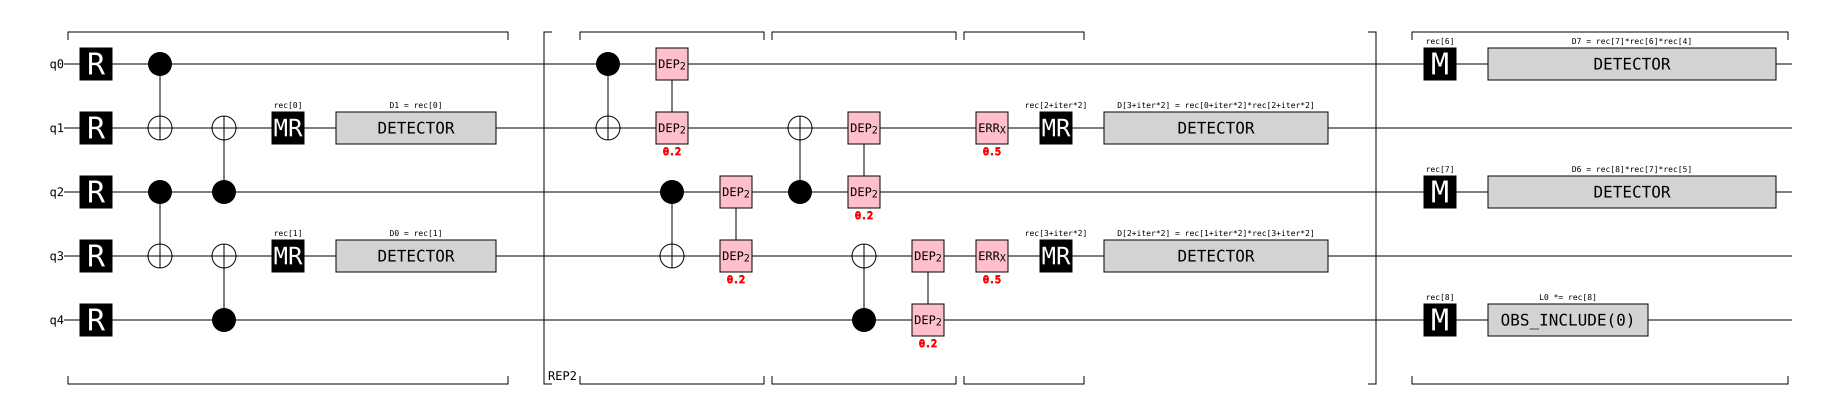

In [36]:
circuit.diagram("timeline-svg")

In [6]:
import numpy as np
import pandas as pd
import pymatching
from qiskit_ibm_runtime.fake_provider import (
    FakeBoston,
    FakeKingston,
    FakeMiami,
)
import stim
pd.set_option("display.float_format", "{:.10f}".format)
# 1. Your 4 selected backends
backends = [FakeBoston(), FakeKingston(), FakeMiami()]


# 2. Repetition code function
def repetition_code(
    distance: int, p_2q: float, p_meas: float, rounds: int = 3
) -> stim.Circuit:
    circuit = stim.Circuit()
    n_qubits = 2 * distance - 1
    ancillas = list(range(1, n_qubits, 2))
    datas = list(range(0, n_qubits, 2))

    circuit.append("R", range(n_qubits))
    for i in ancillas:
        circuit.append("CX", [i - 1, i])
        circuit.append("DEPOLARIZE2", [i - 1, i], p_2q)
    for i in ancillas:
        circuit.append("CX", [i + 1, i])
        circuit.append("DEPOLARIZE2", [i + 1, i], p_2q)
    circuit.append("X_ERROR", ancillas, p_meas)
    circuit.append("MR", ancillas)

    for i in range(1, distance):
        circuit.append("DETECTOR", [stim.target_rec(-i)])

    rnd = stim.Circuit()
    for i in ancillas:
        rnd.append("CX", [i - 1, i])
        rnd.append("DEPOLARIZE2", [i - 1, i], p_2q)
    rnd.append("TICK")
    for i in ancillas:
        rnd.append("CX", [i + 1, i])
        rnd.append("DEPOLARIZE2", [i + 1, i], p_2q)
    rnd.append("TICK")
    rnd.append("X_ERROR", ancillas, p_meas)
    rnd.append("MR", ancillas)
    rnd.append("TICK")
    for i in range(1, distance):
        rnd.append(
            "DETECTOR",
            [stim.target_rec(-i - (distance - 1)), stim.target_rec(-i)],
        )

    circuit += (rounds - 1) * rnd

    circuit.append("X_ERROR", datas, p_meas)
    circuit.append("M", datas)
    for i in range(1, distance):
        circuit.append(
            "DETECTOR",
            [
                stim.target_rec(-i),
                stim.target_rec(-i - 1),
                stim.target_rec(-i - distance),
            ],
        )
    circuit.append("OBSERVABLE_INCLUDE", [stim.target_rec(-1)], 0)
    return circuit


# 3. Collect errors, run simulation, and record
results = []
for b in backends:
    gate_2q = "cz" if "cz" in b.target else "cx"
    p_2q = float(
        np.mean(
            [
                p.error
                for p in b.target[gate_2q].values()
                if p and p.error is not None
            ]
        )
    )
    p_meas = float(
        np.mean(
            [
                p.error
                for p in b.target["measure"].values()
                if p and p.error is not None
            ]
        )
    )

    circ = repetition_code(distance=3, p_2q=p_2q, p_meas=p_meas)
    dem = circ.detector_error_model(decompose_errors=True)
    matching = pymatching.Matching.from_detector_error_model(dem)

    sampler = circ.compile_detector_sampler()
    dets, obs = sampler.sample(200_000, separate_observables=True)
    preds = matching.decode_batch(dets)
    log_err = float(np.mean((obs ^ preds)[:, 0]))

    results.append(
        {
            "backend": b.name,
            "gate_2q_type": gate_2q,
            "p_2q": p_2q,
            "p_meas": p_meas,
            "logical_error_rate": log_err,
        }
    )

# 4. Save to Excel & print table
df = pd.DataFrame(results)
df.to_excel("ibm_characterization.xlsx", index=False)
excel_file = "ibm_characterization.xlsx"
with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:
    df.to_excel(writer, index=False, sheet_name="Characterization")
    ws = writer.sheets["Characterization"]
    # Apply 10 decimal format "0.0000000000" to columns C, D, E
    for col in ["C", "D", "E"]:
        for cell in ws[col][1:]:  # skip header row
            cell.number_format = "0.0000000000"


Logical error rate: 0.001035
<0|Z|0>_L = 0.99793


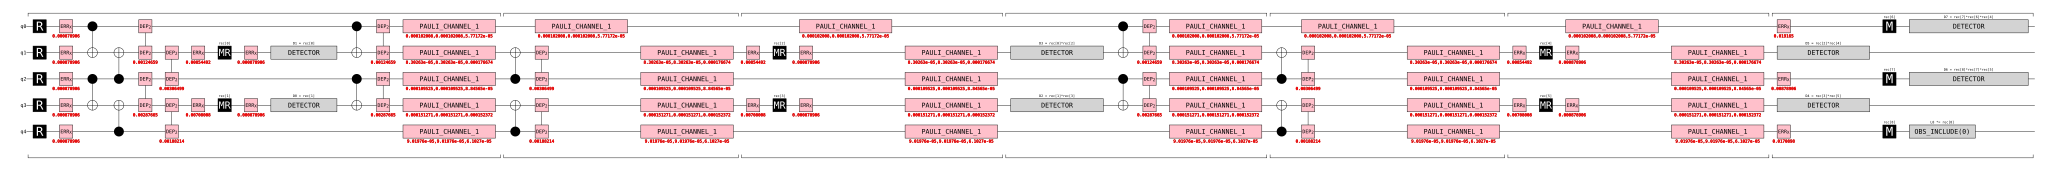

In [53]:
import stim; import numpy as np; import pymatching
from noise_models import apply_noise, model_from_backend, best_chain
from qiskit_ibm_runtime.fake_provider import FakeBoston


ideal = repetition_code(3)


backend = FakeMiami()
chain = best_chain(backend, ideal.num_qubits, "cz")      
circuit = apply_noise(ideal, model_from_backend(backend, chain, "cz"))



# Everything below is identical to your code
dem = circuit.detector_error_model(decompose_errors=True)
matching = pymatching.Matching.from_detector_error_model(dem)

shots = 1_000_000
sampler = circuit.compile_detector_sampler()
detectors, observables = sampler.sample(shots, separate_observables=True)

predictions = matching.decode_batch(detectors)
failures = (observables ^ predictions)[:, 0]

logical_error_rate = np.mean(failures)
expectation = np.mean(1 - 2*failures.astype(np.int8))
print(f"Logical error rate: {logical_error_rate}")
print(f"<0|Z|0>_L = {expectation}")

circuit.diagram('timeline-svg')
